# Práctica: Árboles de Decisión (Clasificación)

**Profesor:** Carlos Tessier Fernández
**Módulo:** Sistemas de aprendizaje automático (SAA) 
**Objetivo:** Aplicar un Árbol de Decisión para clasificar especies de pingüinos [RA3, cite: 785].

---

### Contexto

Vamos a utilizar el dataset `Pinguinos.csv`. El objetivo es entrenar un modelo que pueda predecir la **especie** (`species`) de un pingüino basándose en sus características físicas (longitud del pico, longitud de la aleta, masa corporal, etc.) y su ubicación (`island`, `sex`).

**Target (Objetivo):** `species` (Adelie, Chinstrap, Gentoo)
**Features (Características):** Todas las demás columnas.

### Paso 1: Importar Librerías y Cargar Datos

Importa `pandas`, `train_test_split`, `DecisionTreeClassifier`, `accuracy_score`, `confusion_matrix`, `LabelEncoder` y `plot_tree`.

In [32]:
# HUECO 1.1: Importa todas las librerías necesarias
import pandas as pd
import matplotlib.pyplot as plt
# ... (importa el resto)
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import numpy as np
from sklearn.preprocessing import LabelEncoder

In [41]:
# HUECO 1.2: Carga el dataset 'Pinguinos.csv' en un DataFrame llamado 'df'
df = pd.read_csv('/home/andrescg01/Documentos/IA/PIA/data/penguins.csv')

# HUECO 1.3: Explora los datos (usa .info() y .head())
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


### Paso 2: Preprocesamiento de Datos (Limpieza y Codificación)

Como hemos visto con `.info()`, hay valores nulos (NaN) y columnas de tipo `object` (categóricas) que `scikit-learn` no puede procesar directamente.

**Tarea 2.1: Manejar valores nulos**

Por simplicidad, vamos a eliminar cualquier fila que contenga al menos un valor nulo.

In [42]:
# HUECO 2.1: Elimina las filas con valores nulos (NaN) del DataFrame 'df'
# Pista: usa .dropna()
df.isna().sum()
df=df.dropna()
# Comprueba con df.info() que ya no hay nulos
df.info()


<class 'pandas.DataFrame'>
Index: 333 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            333 non-null    str    
 1   island             333 non-null    str    
 2   bill_length_mm     333 non-null    float64
 3   bill_depth_mm      333 non-null    float64
 4   flipper_length_mm  333 non-null    float64
 5   body_mass_g        333 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 20.8 KB


**Tarea 2.2: Codificar variables categóricas**

Necesitamos convertir las columnas `species` (nuestro target), `island` y `sex` (features) a números.

Ejemplo de uso de ```LabelEncoder```:   
```python
import numpy as np
from sklearn.preprocessing import LabelEncoder

# --- Datos de Ejemplo ---
# Imagina que tenemos datos de una variable categorica (texto).
# 'LabelEncoder' se usa tipicamente para la variable OBJETIVO (la 'y').
# Para las variables FEATURES (la 'X'), es mas comun usar OneHotEncoder,
# pero LabelEncoder tambien se usa a veces si la cardinalidad es baja.

labels = ['Adelie', 'Gentoo', 'Chinstrap', 'Adelie', 'Gentoo']
print(f"Datos Originales: {labels}")
print("---")

# 1. Inicializar el codificador
# Creamos una instancia de la clase
le = LabelEncoder()

# 2. Ajustar y Transformar (fit_transform)
# El metodo .fit_transform() hace dos cosas:
# 1. .fit(): Aprende el mapeo (las clases unicas). Asigna un numero
#            a cada clase por orden alfabetico.
# 2. .transform(): Aplica ese mapeo a los datos.
encoded_labels = le.fit_transform(labels)

print(f"Datos Codificados: {encoded_labels}")
print("---")

# 3. Ver las clases aprendidas
# El atributo .classes_ nos muestra el mapeo.
# El indice del array corresponde al numero asignado.
# (0 -> 'Adelie', 1 -> 'Chinstrap', 2 -> 'Gentoo')
print(f"Clases aprendidas (mapeo): {le.classes_}")
print("---")


# 4. Transformar datos nuevos
# Si aparece un dato que el encoder ya conoce (ej. 'Gentoo')
nuevo_dato = ['Gentoo']
print(f"Dato nuevo: {nuevo_dato}")
print(f"Dato nuevo codificado: {le.transform(nuevo_dato)}")
print("---")

# 5. Invertir la transformacion (inverse_transform)
# Esto es muy util para interpretar las predicciones del modelo.
# Si el modelo predice [2, 0, 1], ¿que especies son?
predicciones_numericas = np.array([2, 0, 1, 0])
predicciones_originales = le.inverse_transform(predicciones_numericas)

print(f"Predicciones (numeros): {predicciones_numericas}")
print(f"Predicciones (texto):   {predicciones_originales}")
```   
OBTENEMOS:    
```
Datos Originales: ['Adelie', 'Gentoo', 'Chinstrap', 'Adelie', 'Gentoo']
---
Datos Codificados: [0 2 1 0 2]
---
Clases aprendidas (mapeo): ['Adelie' 'Chinstrap' 'Gentoo']
---
Dato nuevo: ['Gentoo']
Dato nuevo codificado: [2]
---
Predicciones (numeros): [2 0 1 0]
Predicciones (texto):   ['Gentoo' 'Adelie' 'Chinstrap' 'Adelie']
```   


In [ ]:
# HUECO 2.2.1 (Target): Usa LabelEncoder para convertir la columna 'species'
# 1. Crea una instancia de LabelEncoder
le=LabelEncoder()
# 2. Ajústala y transfórmala sobre df['species']
labels=['Adelie', 'Gentoo', 'Chinstrap']
encoded_labels=le.fit_transform(labels)
# 3. Guarda el resultado en una nueva columna, p.ej. 'species_encoded'
# (Guarda el encoder para referencia futura)
df['species_encoded']=le.transform(df['species'])
df.head()


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,species_encoded
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE,0
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE,0
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE,0
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE,0
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE,0


### ONE-HOT ENCODING   
One-Hot Encoding (OHE) es una técnica de preprocesamiento que convierte una columna de datos categóricos en múltiples columnas binarias (0s y 1s).

Cada categoría única en la columna original se convierte en su propia columna nueva, que actúa como un "interruptor" (0 = apagado, 1 = encendido).   

La solución (OHE): OHE crea tres columnas (ej. isla_Torgersen, isla_Biscoe, isla_Dream).

- Un pingüino de Biscoe será: [0, 1, 0]
- Un pingüino de Dream será: [0, 0, 1]
- Un pingüino de Torgersen será: [1, 0, 0]

```python   
# --- Aplicar One-Hot Encoding ---
# pd.get_dummies() detecta automaticamente las columnas de
# texto (tipo 'object') y las convierte.
#
# Nota: 'especie' es nuestro target, pero lo incluimos
# solo para ver como lo codifica.
df_codificado = pd.get_dummies(df)

```
```python    
# --- OHE y la "Trampa del Chupete" (Dummy Variable Trap) ---
#
# Podemos observar que las columnas son redundantes.
# Si 'isla_Biscoe'=0 e 'isla_Dream'=0, ya SABEMOS que 'isla_Torgersen' debe ser 1.
#
# Esta redundancia (multicolinealidad) puede causar problemas
# en algunos modelos (como la Regresion Lineal).
#
# Solucion: Usar 'drop_first=True' para eliminar la primera
# categoria de cada feature, convirtiendola en la 'base' (todo 0s).
df_codificado_optimizado = pd.get_dummies(df, drop_first=True)

```

In [ ]:
# HUECO 2.2.2 (Features): Usa pd.get_dummies para convertir 'island' y 'sex'
# Esto usará One-Hot Encoding, que es lo ideal para features categóricas en árboles.
df_encoded = pd.get_dummies(df, columns=['island', 'sex'], drop_first=True)
# Muestra el nuevo dataframe
df_encoded.head()

,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,species_encoded,island_Dream,island_Torgersen,sex_MALE
0,Adelie,39.1,18.7,181.0,3750.0,0,False,True,True
1,Adelie,39.5,17.4,186.0,3800.0,0,False,True,False
2,Adelie,40.3,18.0,195.0,3250.0,0,False,True,False
4,Adelie,36.7,19.3,193.0,3450.0,0,False,True,False
5,Adelie,39.3,20.6,190.0,3650.0,0,False,True,True


### Paso 3: Preparar X (Features) e y (Target)

**Tarea 3.1:** Define `y` como la columna codificada del target (`species_encoded`).
**Tarea 3.2:** Define `X` como las columnas numéricas relevantes (las originales + las creadas por `get_dummies`). Asegúrate de NO incluir `species` (la original) ni `species_encoded` (el target) en `X`.

In [53]:
# HUECO 3.1: Define 'y'
y=df_encoded['species_encoded']
# HUECO 3.2: Define 'X'
# Pista: puedes hacer X = df_encoded.drop(columns=['species', 'species_encoded'])
X=df_encoded.drop(columns=['species','species_encoded'])

### Paso 4: División de Datos (Train/Test)

Divide `X` e `y` en conjuntos de entrenamiento y prueba. Usa un `test_size` de 0.3 y un `random_state` de 42.

In [54]:
# HUECO 4: Importa train_test_split (si no lo hiciste) y divide los datos
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)
display(X)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Dream,island_Torgersen,sex_MALE
0,39.1,18.7,181.0,3750.0,False,True,True
1,39.5,17.4,186.0,3800.0,False,True,False
2,40.3,18.0,195.0,3250.0,False,True,False
4,36.7,19.3,193.0,3450.0,False,True,False
5,39.3,20.6,190.0,3650.0,False,True,True
...,...,...,...,...,...,...,...
338,47.2,13.7,214.0,4925.0,False,False,False
340,46.8,14.3,215.0,4850.0,False,False,False
341,50.4,15.7,222.0,5750.0,False,False,True
342,45.2,14.8,212.0,5200.0,False,False,False


### Paso 5: Entrenamiento del Modelo

Crea una instancia de `DecisionTreeClassifier`. Para evitar overfitting, asígnale un `max_depth` (profundidad máxima) de 4 y un `random_state` de 42. Luego, entrénalo.

In [55]:
# HUECO 5: Crea el clasificador (clf) y entrénalo (fit)
clf=DecisionTreeClassifier(criterion='gini',max_depth=3,random_state=42)
clf.fit(X_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

### Paso 6: Evaluación del Modelo

Usa el modelo entrenado para predecir sobre `X_test`. Calcula el `accuracy_score` y la `confusion_matrix`.

In [56]:
# HUECO 6: Realiza predicciones (y_pred) y evalúa el modelo
y_pred=clf.predict(X_test)
print(f"Accuracy (Precisión): {accuracy_score(y_test, y_pred):.2f}")
print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, y_pred))

Accuracy (Precisión): 0.98

Matriz de Confusión:
[[48  0  0]
 [ 2 16  0]
 [ 0  0 34]]


### Paso 7: (Opcional) Visualización

Visualiza el árbol que has entrenado usando `plot_tree`. Necesitarás los nombres de las features (de `X.columns`) y los nombres de las clases (del `LabelEncoder`).

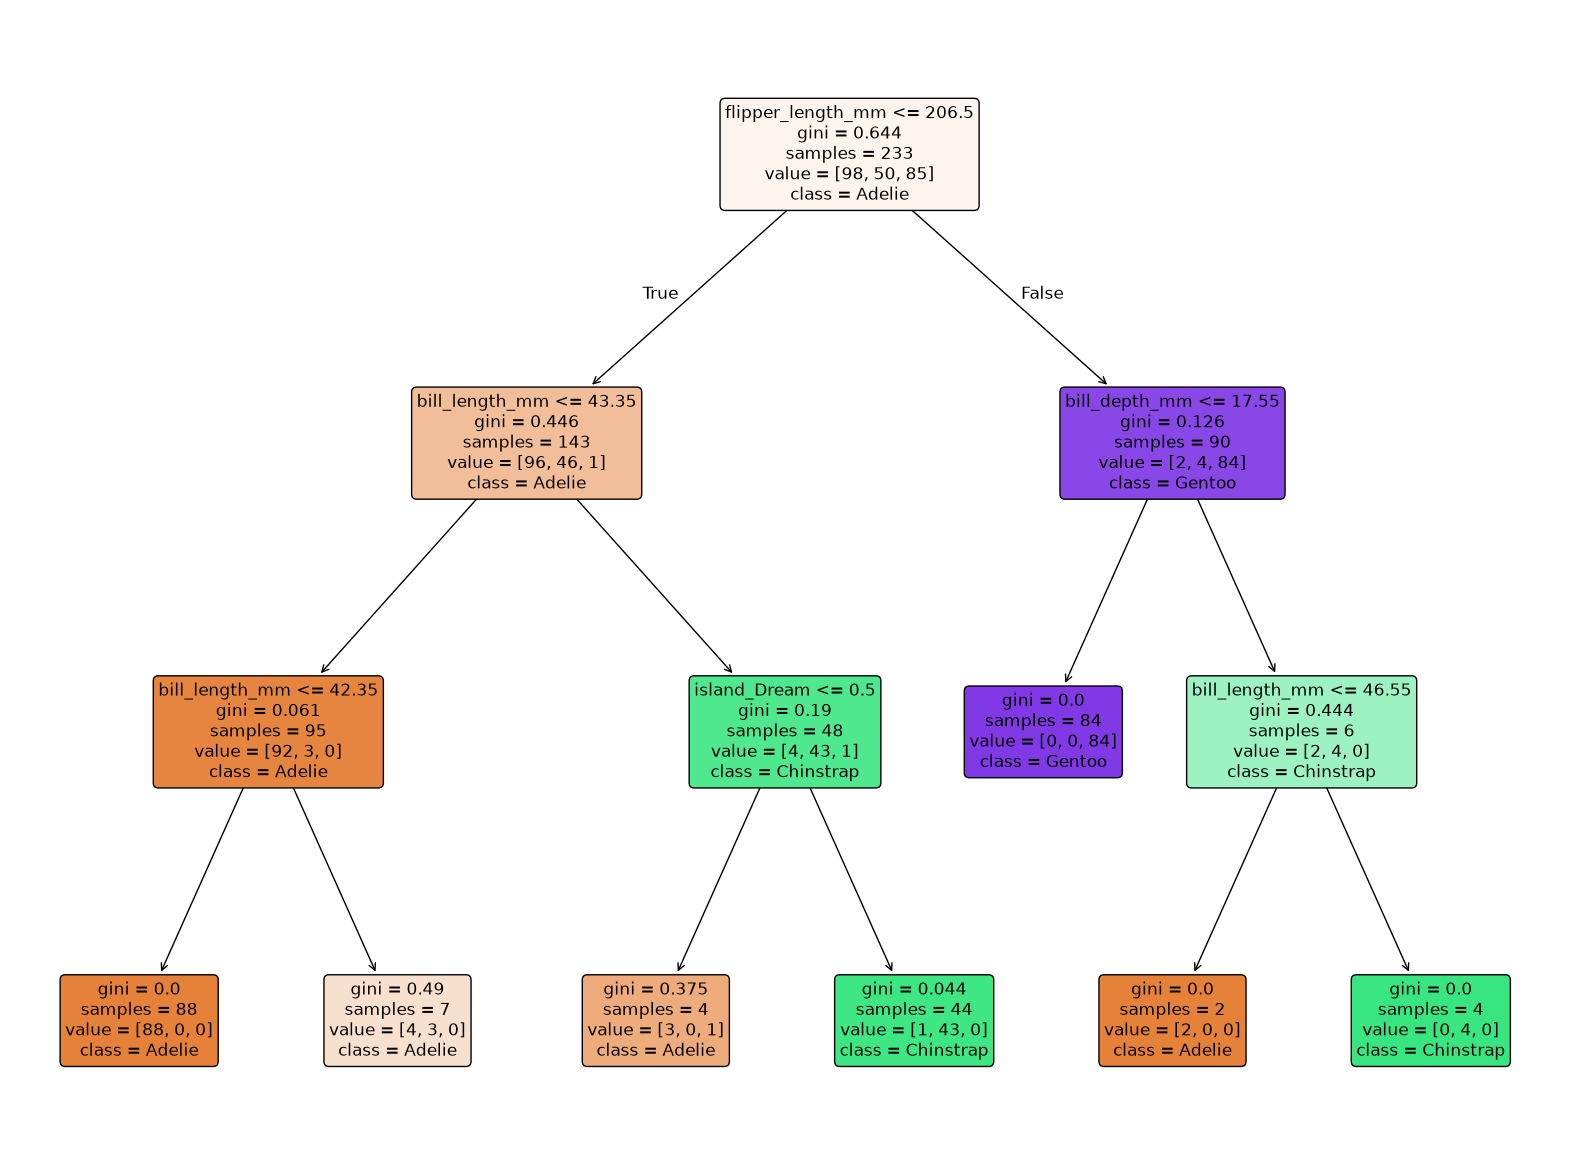

In [57]:
# HUECO 7 (Opcional): Visualiza el árbol

plt.figure(figsize=(20, 15))
plot_tree(clf,
          filled=True,
          rounded=True,
          class_names=le.classes_, # 'le' es el nombre de tu LabelEncoder
          feature_names=X.columns)
plt.show()